# Bài 1.2 - Tìm "vách đá" của quantization (CIFAR-10)
# Bài 1.3 - Cho INT8 thật sự chạy nhanh trên CPU

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/KuSenpai/modelopt101/blob/exercise-1.3-1.4/exercises/1.2_quant_cliff.ipynb)

**Mục tiêu.** Lấy student CNN của bài 1.1, giảm dần số bit của weight từ 8 xuống 2 và tìm
mức bit mà accuracy bắt đầu "rơi xuống vực". So sánh hai cách chọn scale:

- **per-tensor:** cả tensor weight dùng chung một scale;
- **per-channel:** mỗi output channel (mỗi filter) có scale riêng.

Phần làm thêm: viết **QAT (quantization-aware training)** bằng **straight-through estimator (STE)**
rồi so với PTQ ở 4 bit.

```
student Net (bài 1.1, train có KD từ ResNet-18)
   ├─ (b) PTQ weight fake-quant: bits = 8 → 2, per-tensor vs per-channel
   └─ (c) QAT per-channel bằng STE: INT4 (+ INT3, INT2 làm bonus)
```

**Chỉ tiêu:** QAT INT4 mất **≤ 1 điểm %** accuracy so với FP32.

**Bài 1.3** (mục 10 trở đi) dùng lại đúng data và checkpoint `student_kd` ở trên: quantize student sang
INT8 thật (static PTQ, activation cũng INT8, chạy bằng kernel số nguyên) bằng `torch.ao.quantization`
FX graph mode và bằng ONNX Runtime, rồi đo latency CPU so với FP32.
**Chỉ tiêu 1.3:** latency giảm **≥ 2 lần** so với FP32.

**Runtime:** `Runtime -> Change runtime type -> GPU (T4)`, rồi `Runtime -> Run all`.
Khoảng 35 phút cho 1.2 và 5 phút cho 1.3, chưa tính thời gian tải CIFAR-10.
Notebook sẽ hỏi quyền mount Google Drive: cho phép thì checkpoint và CIFAR-10 được lưu ở
`MyDrive/modelopt101_ckpt` / `MyDrive/modelopt101_data`, lần chạy sau khỏi train và tải lại.
Từ chối thì notebook vẫn chạy, chỉ lưu tạm trong `/content`.

## 1. Setup

In [1]:
import os, io, time, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.nn.utils.parametrize as P
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as T
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"     # mixed precision: ~2x faster training on T4
print("device:", torch.cuda.get_device_name(0) if USE_AMP else "cpu")

# --- knobs you can play with ---
EPOCHS_TEACHER  = 15
EPOCHS_STUDENT  = 20
QAT_EPOCHS      = 8
BATCH_SIZE      = 256
LR              = 0.1
QAT_LR          = 0.01          # low LR: QAT only nudges an already-trained model
T_KD, ALPHA_KD  = 4.0, 0.7      # distillation temperature / weight on the teacher term
BITS            = [8, 7, 6, 5, 4, 3, 2]
QAT_BITS        = [4, 3, 2]     # 4 is the target, 3 and 2 are the bonus

# checkpoints + CIFAR-10 files live on Google Drive when it can be mounted, so a fresh
# Colab runtime neither retrains nor re-downloads; otherwise fall back to local dirs.
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:          # not on Colab, or Drive access was not granted
    print("Google Drive not mounted:", type(e).__name__)
ON_DRIVE = os.path.isdir("/content/drive/MyDrive")
CKPT_DIR = "/content/drive/MyDrive/modelopt101_ckpt" if ON_DRIVE else "./ckpt"
DATA_DIR = "/content/drive/MyDrive/modelopt101_data" if ON_DRIVE else "./data"
os.makedirs(CKPT_DIR, exist_ok=True)
print("checkpoints ->", CKPT_DIR, "| data ->", DATA_DIR)

device: Tesla T4
checkpoints -> ./ckpt


## 2. Data - CIFAR-10

Giống hệt bài 1.1: random crop có padding + lật ngang, normalize theo mean/std của CIFAR-10.

In [2]:
mean, std = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
train_tf = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(),
                      T.ToTensor(), T.Normalize(mean, std)])
test_tf  = T.Compose([T.ToTensor(), T.Normalize(mean, std)])

train_set = torchvision.datasets.CIFAR10(DATA_DIR, train=True,  download=True, transform=train_tf)
test_set  = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True, transform=test_tf)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2,
                          pin_memory=True, drop_last=True)
test_loader  = DataLoader(test_set,  batch_size=512,        shuffle=False, num_workers=2,
                          pin_memory=True)
print(len(train_set), "train /", len(test_set), "test images")

100%|██████████| 170M/170M [26:21<00:00, 108kB/s] 


50000 train / 10000 test images


## 3. Models

Cùng hai kiến trúc với bài 1.1: teacher ResNet-18 (stem CIFAR) và student CNN kiểu VGG 6 conv.

In [3]:
def make_teacher(num_classes=10):
    m = torchvision.models.resnet18(num_classes=num_classes)
    m.conv1 = nn.Conv2d(3, 64, 3, stride=1, padding=1, bias=False)   # CIFAR stem
    m.maxpool = nn.Identity()
    return m

def conv_block(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False),
                         nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class Net(nn.Module):
    def __init__(self, widths=(64, 64, 128, 128, 256, 256), num_classes=10):
        super().__init__()
        w = widths
        self.features = nn.Sequential(
            conv_block(3,    w[0]), conv_block(w[0], w[1]), nn.MaxPool2d(2),   # 32 -> 16
            conv_block(w[1], w[2]), conv_block(w[2], w[3]), nn.MaxPool2d(2),   # 16 -> 8
            conv_block(w[3], w[4]), conv_block(w[4], w[5]), nn.MaxPool2d(2),   # 8  -> 4
        )
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(w[5], num_classes))
        self.widths = tuple(widths)

    def forward(self, x):
        return self.head(self.features(x))

def count_params(m):
    return sum(p.numel() for p in m.parameters())

print(f"teacher params: {count_params(make_teacher()):,}")
print(f"student params: {count_params(Net()):,}")

teacher params: 11,173,962
student params: 1,148,874


## 4. Train / eval / quantization utilities

`train`, `evaluate`, `distillation_loss`, `quantize` / `dequantize` / `quantize_model` chép nguyên
từ bài 1.1. Thêm `train_or_load` để lưu checkpoint: chạy lại notebook thì không phải train lại.

In [4]:
def train(model, loss_fn, epochs, lr=LR, tag=""):
    model.to(device).train()
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, nesterov=True, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, epochs=epochs,
                                                steps_per_epoch=len(train_loader))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    for ep in range(epochs):
        t0 = time.time()
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device.type, enabled=USE_AMP):
                loss = loss_fn(model(x), x, y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
        print(f"[{tag}] epoch {ep+1:02d}/{epochs}  test_acc={evaluate(model):.2f}%  ({time.time()-t0:.0f}s)")
    return model

@torch.no_grad()
def evaluate(model):
    model.to(device).eval()
    correct = total = 0
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        correct += (model(x).argmax(1) == y).sum().item()
        total += y.numel()
    model.train()
    return 100.0 * correct / total

def model_size_mb(state_dict):
    buf = io.BytesIO()
    torch.save(state_dict, buf)
    return buf.getbuffer().nbytes / 1e6

def train_or_load(name, model, loss_fn, epochs, **kw):
    path = os.path.join(CKPT_DIR, name + ".pt")
    if os.path.exists(path):
        model.load_state_dict(torch.load(path, map_location="cpu"))
        print(f"[{name}] loaded checkpoint {path}")
    else:
        train(model, loss_fn, epochs, tag=name, **kw)
        torch.save(model.state_dict(), path)
        print(f"[{name}] saved checkpoint {path}")
    return model.to(device).eval()

ce_loss = lambda out, x, y: F.cross_entropy(out, y)

def distillation_loss(student_logits, teacher_logits, labels, T=T_KD, alpha=ALPHA_KD):
    ce_term = F.cross_entropy(student_logits, labels)
    kd_term = F.kl_div(F.log_softmax(student_logits.float() / T, dim=1),
                       F.softmax(teacher_logits.float() / T, dim=1),
                       reduction="batchmean") * T ** 2
    return alpha * kd_term + (1 - alpha) * ce_term

def quantize(x, n_bits=8, symmetric=True, per_channel=False):
    qmin, qmax = -(2 ** (n_bits - 1)), 2 ** (n_bits - 1) - 1
    if per_channel:
        flat = x.flatten(1)
        xmin, xmax = flat.min(1).values, flat.max(1).values
    else:
        xmin, xmax = x.min(), x.max()
    if symmetric:
        scale = (torch.maximum(xmin.abs(), xmax.abs()) / qmax).clamp(min=1e-8)
        zero_point = torch.zeros_like(scale)
    else:
        scale = ((xmax - xmin) / (qmax - qmin)).clamp(min=1e-8)
        zero_point = qmin - torch.round(xmin / scale)
    shape = [-1] + [1] * (x.dim() - 1)
    s = scale.view(shape) if per_channel else scale
    z = zero_point.view(shape) if per_channel else zero_point
    q = torch.clamp(torch.round(x / s) + z, qmin, qmax)
    return q, scale, zero_point

def dequantize(q, scale, zero_point, per_channel=False):
    if per_channel:
        shape = [-1] + [1] * (q.dim() - 1)
        scale, zero_point = scale.view(shape), zero_point.view(shape)
    return scale * (q - zero_point)

QUANTIZABLE = (nn.Conv2d, nn.Linear)

def quantize_model(model, n_bits=8, per_channel=True):
    """Return (packed_state_dict, dequantized_model) for weight-only PTQ."""
    packed = {}
    deq = copy.deepcopy(model).cpu().eval()
    qnames = [n for n, m in deq.named_modules() if isinstance(m, QUANTIZABLE)]
    for name, mod in deq.named_modules():
        if isinstance(mod, QUANTIZABLE):
            q, s, z = quantize(mod.weight.data, n_bits=n_bits, per_channel=per_channel)
            packed[name + ".weight_int"]   = q.to(torch.int8)
            packed[name + ".weight_scale"] = s.clone()
            mod.weight.data = dequantize(q, s, z, per_channel=per_channel)
    for k, v in deq.state_dict().items():
        if k not in {n + ".weight" for n in qnames}:
            packed[k] = v
    return packed, deq

## 5. (a) Model FP32 - student `Net` của bài 1.1, train **có KD**

Làm lại đúng công thức bài 1.1: train teacher ResNet-18 15 epoch, rồi train student `Net`
(widths 64-64-128-128-256-256) 20 epoch bằng KD loss (T = 4, α = 0.7). Đây là model "1b. student, KD"
của bài 1.1 (lần đó đạt 91.38%). Model này làm **mốc FP32** cho mọi phép so sánh bên dưới.

Ở đây dùng student chưa pruning, để đường cong theo bit chỉ phản ánh quantization chứ không cộng
dồn sai số của pruning. Checkpoint lưu ở `CKPT_DIR`.

In [5]:
teacher = train_or_load("teacher_resnet18", make_teacher(), ce_loss, EPOCHS_TEACHER)
print(f"teacher acc: {evaluate(teacher):.2f}%")
teacher.eval()
for p in teacher.parameters():
    p.requires_grad_(False)

def kd_loss_fn(student_out, x, y):
    with torch.no_grad():
        teacher_out = teacher(x)
    return distillation_loss(student_out, teacher_out, y)

student = train_or_load("student_kd", Net(), kd_loss_fn, EPOCHS_STUDENT)
fp32_acc = evaluate(student)
print(f"\nFP32 student (KD) acc: {fp32_acc:.2f}%   size: {model_size_mb(student.state_dict()):.2f} MB")

[teacher_resnet18] epoch 01/15  test_acc=48.39%  (27s)
[teacher_resnet18] epoch 02/15  test_acc=59.47%  (24s)
[teacher_resnet18] epoch 03/15  test_acc=71.07%  (24s)
[teacher_resnet18] epoch 04/15  test_acc=76.15%  (25s)
[teacher_resnet18] epoch 05/15  test_acc=78.14%  (27s)
[teacher_resnet18] epoch 06/15  test_acc=79.55%  (28s)
[teacher_resnet18] epoch 07/15  test_acc=79.07%  (26s)
[teacher_resnet18] epoch 08/15  test_acc=83.89%  (26s)
[teacher_resnet18] epoch 09/15  test_acc=84.99%  (27s)
[teacher_resnet18] epoch 10/15  test_acc=85.67%  (27s)
[teacher_resnet18] epoch 11/15  test_acc=85.58%  (27s)
[teacher_resnet18] epoch 12/15  test_acc=88.04%  (27s)
[teacher_resnet18] epoch 13/15  test_acc=90.42%  (27s)
[teacher_resnet18] epoch 14/15  test_acc=90.85%  (27s)
[teacher_resnet18] epoch 15/15  test_acc=91.20%  (27s)
[teacher_resnet18] saved checkpoint ./ckpt/teacher_resnet18.pt
teacher acc: 91.20%
[student_kd] epoch 01/20  test_acc=56.82%  (22s)
[student_kd] epoch 02/20  test_acc=72.35%  

## 6. (b) PTQ: quét bits 8 → 2, per-tensor vs per-channel

Weight-only fake-quant, symmetric: mọi `Conv2d` và `Linear` (kể cả conv đầu và lớp cuối) được
làm tròn về lưới `n_bits` rồi dequantize về FP32. BatchNorm và activation giữ FP32.

Với symmetric `n_bits`, lưới có các mức nguyên trong `[-2^(b-1), 2^(b-1) - 1]`, nên 2 bit chỉ còn
4 mức `{-2, -1, 0, 1} × scale`. Per-tensor dùng một scale `max|W| / qmax` cho cả lớp; chỉ cần một
filter có weight lớn là mọi filter khác bị làm tròn thô.

"Vách đá" = mức bit đầu tiên (đi từ 8 xuống) mà accuracy giảm **quá 1 điểm** và **quá 5 điểm** so với FP32.

FP32: 91.34%

bits | per-tensor       Δ | per-channel       Δ
------------------------------------------------
   8 |     91.33%   -0.01 |      91.33%   -0.01
   7 |     91.41%   +0.07 |      91.37%   +0.03
   6 |     91.12%   -0.22 |      91.26%   -0.08
   5 |     90.74%   -0.60 |      91.24%   -0.10
   4 |     88.85%   -2.49 |      90.41%   -0.93
   3 |     64.53%  -26.81 |      86.82%   -4.52
   2 |     10.00%  -81.34 |      11.22%  -80.12

per-tensor   cliff: first bit with >1 pt drop = 4, >5 pt drop = 3
per-channel  cliff: first bit with >1 pt drop = 3, >5 pt drop = 2


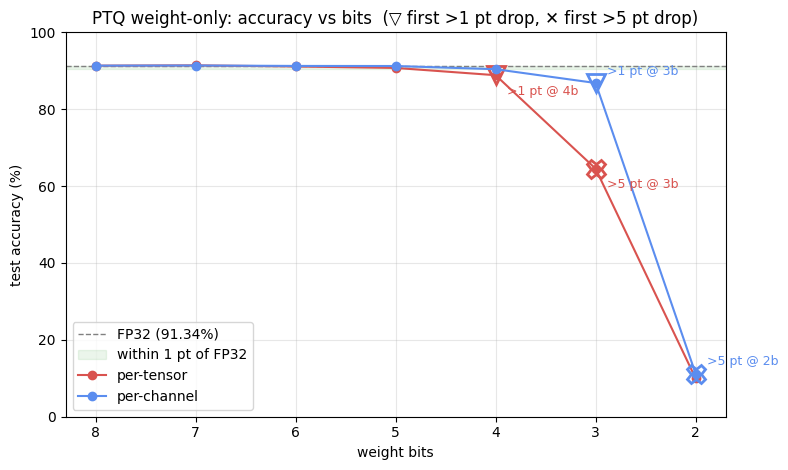

In [6]:
ptq = {"per-tensor": {}, "per-channel": {}}
for b in BITS:
    for gran in ptq:
        ptq[gran][b] = evaluate(quantize_model(student, n_bits=b, per_channel=(gran == "per-channel"))[1])

def first_drop(accs, thr):
    for b in BITS:                          # BITS goes 8 -> 2
        if fp32_acc - accs[b] > thr:
            return b
    return None

print(f"FP32: {fp32_acc:.2f}%\n")
print(f"{'bits':>4} | {'per-tensor':>10} {'Δ':>7} | {'per-channel':>11} {'Δ':>7}")
print("-" * 48)
for b in BITS:
    t, c = ptq["per-tensor"][b], ptq["per-channel"][b]
    print(f"{b:>4} | {t:>9.2f}% {t-fp32_acc:>+7.2f} | {c:>10.2f}% {c-fp32_acc:>+7.2f}")

cliff = {g: {thr: first_drop(ptq[g], thr) for thr in (1, 5)} for g in ptq}
print()
for g in ptq:
    print(f"{g:<12} cliff: first bit with >1 pt drop = {cliff[g][1]}, >5 pt drop = {cliff[g][5]}")

colors = {"per-tensor": "#d9534f", "per-channel": "#5b8def"}
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.axhline(fp32_acc, color="gray", ls="--", lw=1, label=f"FP32 ({fp32_acc:.2f}%)")
ax.axhspan(fp32_acc - 1, fp32_acc, color="green", alpha=0.08, label="within 1 pt of FP32")
for g, accs in ptq.items():
    ax.plot(BITS, [accs[b] for b in BITS], "o-", color=colors[g], label=g)
    for thr, marker in ((1, "v"), (5, "X")):
        b = cliff[g][thr]
        if b is not None:
            ax.plot(b, accs[b], marker, ms=13, mfc="none", mec=colors[g], mew=2)
            ax.annotate(f">{thr} pt @ {b}b", (b, accs[b]), textcoords="offset points",
                        xytext=(8, -14 if g == "per-tensor" else 6), color=colors[g], fontsize=9)
ax.set_xticks(BITS); ax.invert_xaxis()
ax.set_xlabel("weight bits"); ax.set_ylabel("test accuracy (%)")
ax.set_title("PTQ weight-only: accuracy vs bits  (▽ first >1 pt drop, ✕ first >5 pt drop)")
ax.set_ylim(0, 100); ax.grid(alpha=0.3); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

## 7. (c) QAT bằng straight-through estimator

Khi train, forward dùng weight đã fake-quant $\hat w = \mathrm{deq}(\mathrm{q}(w))$, nhưng `round` có
đạo hàm bằng 0 gần như khắp nơi nên gradient không đi qua được. STE coi phép làm tròn là hàm đồng
nhất khi backward:

$$\hat w_{\text{STE}} = w + \big(\mathrm{deq}(\mathrm{q}(w)) - w\big).\mathrm{detach}()
\quad\Rightarrow\quad \text{forward} = \hat w,\;\; \frac{\partial \hat w_{\text{STE}}}{\partial w} = 1$$

Model giữ một bản weight FP32 "ẩn" $w$, optimizer cập nhật $w$, còn mạng luôn nhìn thấy $\hat w$.
Nhờ vậy mạng học cách chịu được sai số làm tròn. Cài đặt bằng `torch.nn.utils.parametrize`: mỗi
`Conv2d`/`Linear` được gắn module `FakeQuantSTE` (per-channel), `layer.weight` trả về $\hat w_{\text{STE}}$.

Fine-tune từ checkpoint FP32, `QAT_EPOCHS` epoch, LR thấp (`QAT_LR`), dùng cùng KD loss như lúc train student.
Sau QAT, bỏ parametrization để lấy lại $w$ rồi đưa qua đúng `quantize_model` của phần PTQ, tức là
accuracy QAT được đo trên **cùng một kiểu model INT-n** với PTQ.

In [7]:
class FakeQuantSTE(nn.Module):
    """Parametrization: weight -> per-channel symmetric fake-quant, identity gradient (STE)."""
    def __init__(self, n_bits):
        super().__init__()
        self.n_bits = n_bits

    def forward(self, w):
        w_q = dequantize(*quantize(w, self.n_bits, per_channel=True), per_channel=True)
        return w + (w_q - w).detach()

def qat(fp32_model, n_bits, epochs=QAT_EPOCHS, lr=QAT_LR):
    m = copy.deepcopy(fp32_model)
    layers = [mod for mod in m.modules() if isinstance(mod, QUANTIZABLE)]
    for mod in layers:
        P.register_parametrization(mod, "weight", FakeQuantSTE(n_bits))
    print(f"[QAT-INT{n_bits}] start (fake-quant, no training): {evaluate(m):.2f}%")
    train(m, kd_loss_fn, epochs, lr=lr, tag=f"QAT-INT{n_bits}")
    fq_acc = evaluate(m)
    for mod in layers:      # drop the fake-quant wrapper, keep the latent FP32 weights
        P.remove_parametrizations(mod, "weight", leave_parametrized=False)
    packed, deq = quantize_model(m, n_bits=n_bits, per_channel=True)
    acc = evaluate(deq)
    print(f"[QAT-INT{n_bits}] fake-quant acc {fq_acc:.2f}%  ->  exported INT{n_bits} model acc {acc:.2f}%")
    return acc

qat_acc = {}
for b in QAT_BITS:
    qat_acc[b] = qat(student, b)
    print()

[QAT-INT4] start (fake-quant, no training): 90.41%
[QAT-INT4] epoch 01/8  test_acc=91.19%  (23s)
[QAT-INT4] epoch 02/8  test_acc=91.13%  (21s)
[QAT-INT4] epoch 03/8  test_acc=91.24%  (23s)
[QAT-INT4] epoch 04/8  test_acc=91.15%  (22s)
[QAT-INT4] epoch 05/8  test_acc=91.16%  (22s)
[QAT-INT4] epoch 06/8  test_acc=91.25%  (22s)
[QAT-INT4] epoch 07/8  test_acc=91.34%  (22s)
[QAT-INT4] epoch 08/8  test_acc=91.45%  (21s)
[QAT-INT4] fake-quant acc 91.45%  ->  exported INT4 model acc 91.45%

[QAT-INT3] start (fake-quant, no training): 86.82%
[QAT-INT3] epoch 01/8  test_acc=90.24%  (21s)
[QAT-INT3] epoch 02/8  test_acc=90.32%  (23s)
[QAT-INT3] epoch 03/8  test_acc=90.59%  (22s)
[QAT-INT3] epoch 04/8  test_acc=90.34%  (22s)
[QAT-INT3] epoch 05/8  test_acc=90.71%  (22s)
[QAT-INT3] epoch 06/8  test_acc=90.94%  (23s)
[QAT-INT3] epoch 07/8  test_acc=91.05%  (21s)
[QAT-INT3] epoch 08/8  test_acc=91.31%  (23s)
[QAT-INT3] fake-quant acc 91.31%  ->  exported INT3 model acc 91.32%

[QAT-INT2] start (fake

## 8. (d) Tổng kết

model                           acc  Δ vs FP32
----------------------------------------------
FP32 (student KD)            91.34%      +0.00
PTQ INT4 per-tensor          88.85%      -2.49
PTQ INT4 per-channel         90.41%      -0.93
QAT INT4 per-channel         91.45%      +0.11

PTQ INT3 per-tensor          64.53%     -26.81
PTQ INT3 per-channel         86.82%      -4.52
QAT INT3 per-channel         91.32%      -0.02

PTQ INT2 per-tensor          10.00%     -81.34
PTQ INT2 per-channel         11.22%     -80.12
QAT INT2 per-channel         89.40%      -1.94

target: QAT INT4 drop <= 1 pt  ->  drop = -0.11 pt  ->  PASS
QAT INT4 recovers +1.04 pt over PTQ INT4 per-channel


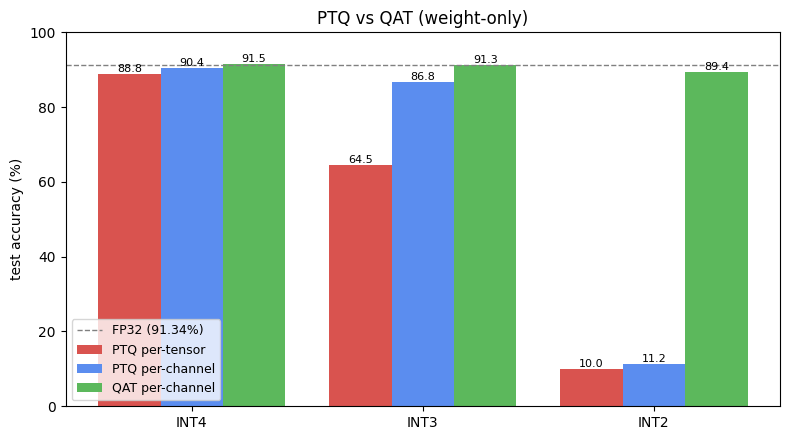

In [8]:
print(f"{'model':<26}{'acc':>9}{'Δ vs FP32':>11}")
print("-" * 46)
print(f"{'FP32 (student KD)':<26}{fp32_acc:>8.2f}%{0:>+11.2f}")
for b in QAT_BITS:
    for name, acc in ((f"PTQ INT{b} per-tensor", ptq["per-tensor"][b]),
                      (f"PTQ INT{b} per-channel", ptq["per-channel"][b]),
                      (f"QAT INT{b} per-channel", qat_acc[b])):
        print(f"{name:<26}{acc:>8.2f}%{acc-fp32_acc:>+11.2f}")
    print()

drop4 = fp32_acc - qat_acc[4]
print(f"target: QAT INT4 drop <= 1 pt  ->  drop = {drop4:.2f} pt  ->  {'PASS' if drop4 <= 1 else 'FAIL'}")
print(f"QAT INT4 recovers {qat_acc[4] - ptq['per-channel'][4]:+.2f} pt over PTQ INT4 per-channel")

x = np.arange(len(QAT_BITS)); w = 0.27
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, (name, vals, c) in enumerate((
        ("PTQ per-tensor",  [ptq["per-tensor"][b]  for b in QAT_BITS], "#d9534f"),
        ("PTQ per-channel", [ptq["per-channel"][b] for b in QAT_BITS], "#5b8def"),
        ("QAT per-channel", [qat_acc[b]            for b in QAT_BITS], "#5cb85c"))):
    bars = ax.bar(x + (i - 1) * w, vals, w, label=name, color=c)
    ax.bar_label(bars, fmt="%.1f", fontsize=8)
ax.axhline(fp32_acc, color="gray", ls="--", lw=1, label=f"FP32 ({fp32_acc:.2f}%)")
ax.set_xticks(x, [f"INT{b}" for b in QAT_BITS]); ax.set_ylim(0, 100)
ax.set_ylabel("test accuracy (%)"); ax.set_title("PTQ vs QAT (weight-only)")
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout(); plt.show()

## 9. Nhận xét

*Kết quả một lần chạy trên Colab Tesla T4 (một seed), các knob giữ mặc định. FP32 = student KD 91.34%
(teacher 91.20%). Δ tính bằng điểm %.*

**1. Vách đá nằm ở đâu?**
- Từ 8 xuống 5 bit gần như không mất gì: per-channel giảm tối đa 0.10 điểm, per-tensor tối đa 0.60 điểm.
  Các dao động ±0.1 ở 7–8 bit (ví dụ 7 bit per-tensor +0.07) là nhiễu.
- **Per-tensor:** giảm quá 1 điểm từ **4 bit** (88.85%, −2.49), quá 5 điểm từ **3 bit** (64.53%, −26.81).
- **Per-channel:** lùi vách đá đi một bit. 4 bit vẫn trong ngưỡng 1 điểm (90.41%, −0.93), giảm quá 1 điểm
  từ **3 bit** (86.82%, −4.52), quá 5 điểm từ **2 bit** (11.22%, −80.12).
- Ở 2 bit cả hai cách đều sụp về mức đoán ngẫu nhiên (10.00% và 11.22%).

**2. Vì sao per-channel tốt hơn per-tensor?**
Per-tensor dùng một scale `max|W| / qmax` cho cả lớp, nên filter có weight lớn nhất quyết định bước làm tròn
của mọi filter khác. Filter có weight nhỏ chỉ dùng được vài mức của lưới. Per-channel cho mỗi filter một scale
riêng nên mỗi filter dùng hết lưới. Khác biệt lộ rõ khi lưới thưa: 4 bit chênh 1.56 điểm, 3 bit chênh
**22.29 điểm** (86.82% so với 64.53%). Ở 2 bit, lưới symmetric chỉ còn 4 mức `{-2, -1, 0, 1} × scale` với
`scale = max|w|`, mọi weight có `|w| < 0.5·max|w|` bị làm tròn về 0, nên dù chia scale theo kênh cũng không cứu được.

**3. QAT bằng STE so với PTQ ở 4 bit — đạt chỉ tiêu?**
**PASS.** QAT INT4 đạt **91.45%**, cao hơn FP32 0.11 điểm (chỉ tiêu: mất ≤ 1 điểm), cao hơn PTQ INT4
per-channel 1.04 điểm và per-tensor 2.60 điểm. Một số điểm cần nói rõ:
- PTQ INT4 per-channel đã mất 0.93 điểm, tức là cũng vừa lọt ngưỡng nhưng chỉ dư 0.07. QAT cho biên an toàn rộng hơn nhiều.
- QAT hồi phục rất nhanh: ngay epoch 1 đã lên 91.19% (từ 90.41%).
- QAT INT4 nhỉnh hơn FP32 một phần vì QAT là thêm 8 epoch fine-tune bằng KD. Muốn so sánh hoàn toàn công bằng
  thì cần fine-tune FP32 thêm 8 epoch như vậy làm mốc. Chênh +0.11 cũng nằm trong mức nhiễu của một seed.
- Accuracy đo trên model INT-n xuất ra (bỏ parametrization, chạy `quantize_model` trên weight ẩn) khớp với
  accuracy fake-quant lúc train (sai khác ≤ 0.01 điểm), tức STE train đúng thứ sẽ được triển khai.

**4. Bonus: QAT 3 bit và 2 bit**
- **INT3:** 86.82% → **91.32%** (−0.02 so với FP32), cũng đạt ngưỡng 1 điểm. Với QAT, vách đá 3 bit biến mất.
- **INT2:** 11.22% → **89.40%** (−1.94), hồi phục 78 điểm nhưng chưa vào ngưỡng 1 điểm. Đường học còn dao động
  (77.97 → 80.17 → 77.30 → 83.72 ...) và vẫn đang tăng ở epoch cuối (86.86 → 89.40), nên nhiều khả năng thêm epoch
  sẽ còn lên. Hướng thử: tăng `QAT_EPOCHS` cho 2 bit, giữ conv đầu và lớp cuối ở 8 bit, hoặc học scale (LSQ)
  thay vì lấy `max|w|`.

**5. Giới hạn của thí nghiệm**
- Weight-only: activation vẫn FP32, BatchNorm chưa fold vào conv. Fold BN sẽ đổi phân bố weight per-channel và
  có thể dời vách đá.
- Bản packed vẫn lưu số nguyên trong `int8`, nên 4/3/2 bit chưa giảm size thật. Muốn có size nhỏ hơn cần nén 2 số
  INT4 (hoặc 4 số INT2) vào một byte. Về lý thuyết weight INT4 nhỏ hơn FP32 8 lần.
- Một seed. Student FP32 lần này đạt 91.34%, so với 91.38% ở bài 1.1 dù teacher giống hệt (91.20%), do GPU không
  hoàn toàn tất định.

---
# Bài 1.3 - Cho INT8 thật sự chạy nhanh

## 10. Vì sao INT8 ở notebook 01 (và bài 1.1) không nhanh hơn?

PTQ ở trên là **weight-only fake-quant**: weight được làm tròn về lưới INT8 rồi **dequantize ngược về FP32**,
activation vẫn FP32, và mọi phép conv vẫn chạy bằng kernel FP32. Model nhỏ hơn khi lưu, nhưng số phép tính
và kiểu phép tính không đổi, nên latency không đổi.

Muốn nhanh thật thì phải **static quantization**: cả weight lẫn activation là INT8, conv chạy bằng kernel số
nguyên (`int8 × int8 → int32`, rồi requantize). Trên CPU x86, kernel này dùng lệnh SIMD số nguyên
(AVX2 `vpmaddubsw`, AVX-512 VNNI `vpdpbusd`), mỗi lệnh xử lý gấp 4 lần số phần tử so với FP32. Scale của
activation phải biết trước, nên cần **calibration**: chạy vài trăm ảnh qua model có gắn observer để ghi lại
khoảng giá trị của từng activation.

Hai cách làm:

| | PyTorch `torch.ao.quantization` FX | ONNX Runtime |
|---|---|---|
| Đầu vào | `nn.Module` | file `.onnx` (BN đã fold vào conv) |
| Fuse | `prepare_fx` tự fuse Conv + BN + ReLU | ORT graph optimizer fuse khi tạo session |
| Calibration | observer MinMax/Histogram, gọi model trên 512 ảnh train | `CalibrationDataReader`, cùng 512 ảnh |
| Kernel | `quantized::conv2d_relu` (backend `x86` = fbgemm + oneDNN) | `QLinearConv` / `ConvInteger` của MLAS |
| Weight | INT8 per-channel, activation UINT8 per-tensor | như bên trái (QDQ format, U8S8) |

**Đo đạc.** CPU của runtime Colab, `torch.set_num_threads` cố định (ORT cũng dùng đúng số luồng đó), warmup
rồi lấy **median** của nhiều lần chạy, batch 1 và batch 64, input ngẫu nhiên kích thước `3×32×32`.
Accuracy đo trên cả 10k ảnh test, kích thước là kích thước file đã lưu.
Mốc FP32 chính là student `student_kd` chạy eager (đúng như bài 1.1); thêm một mốc FP32 đã fold BN để thấy
phần tăng tốc nào chỉ đến từ việc fuse.

In [ ]:
# ---- Bài 1.3 setup: CPU, threads, quantized engine, ONNX packages ----
import importlib.util, platform, statistics, subprocess, sys
missing = [p for p in ("onnx", "onnxruntime", "onnxscript") if importlib.util.find_spec(p) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
import onnx
import onnxruntime as ort
from onnxruntime.quantization import (quantize_static, CalibrationDataReader, QuantFormat, QuantType,
                                      quant_pre_process)
from torch.ao.quantization import get_default_qconfig_mapping
from torch.ao.quantization.quantize_fx import prepare_fx, convert_fx
from torch.nn.utils.fusion import fuse_conv_bn_eval

NUM_THREADS = os.cpu_count()          # fixed for every measurement below (torch and ORT)
torch.set_num_threads(NUM_THREADS)
ENGINE = next(e for e in ("x86", "fbgemm", "onednn") if e in torch.backends.quantized.supported_engines)
torch.backends.quantized.engine = ENGINE
N_CALIB = 512                         # calibration images, taken from the train split
WARMUP  = {1: 50, 64: 5}              # per batch size
ITERS   = {1: 300, 64: 40}
EXPORT_DIR = "./export_1_3"
os.makedirs(EXPORT_DIR, exist_ok=True)

cpu_name, isa = platform.processor() or platform.machine(), []
try:
    lines = open("/proc/cpuinfo").read().splitlines()
    cpu_name = next(l.split(":", 1)[1].strip() for l in lines if l.startswith("model name"))
    flags = next(l for l in lines if l.startswith("flags")).split()
    isa = [f for f in ("avx2", "avx512f", "avx512_vnni", "avx_vnni", "amx_int8") if f in flags]
except (OSError, StopIteration):
    pass
print(f"CPU: {cpu_name} | logical cores: {os.cpu_count()} | int SIMD: {isa}")
print(f"torch {torch.__version__} | threads {torch.get_num_threads()} | quantized engine {ENGINE} "
      f"| onnxruntime {ort.__version__}")

## 11. Static PTQ bằng `torch.ao.quantization` (FX graph mode)

`prepare_fx` trace model thành graph, fuse `Conv2d + BatchNorm2d + ReLU` thành một module, và gắn observer
vào mỗi activation. Chạy 512 ảnh train (transform của tập test, không augment) để observer ghi min/max,
rồi `convert_fx` thay mọi module bằng phiên bản INT8 thật (`QuantizedConvReLU2d`, `QuantizedLinear`) và
chèn `quantize_per_tensor` ở đầu, `dequantize` ở cuối mạng.

In [ ]:
calib_full = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True, transform=test_tf)
calib_idx = torch.randperm(len(calib_full), generator=torch.Generator().manual_seed(0))[:N_CALIB]
calib_loader = DataLoader(torch.utils.data.Subset(calib_full, calib_idx.tolist()), batch_size=64)

fp32_cpu = copy.deepcopy(student).cpu().eval()

def fold_bn(model):
    """FP32 copy with every BatchNorm folded into the conv before it (what ONNX / INT8 get too)."""
    m = copy.deepcopy(model).cpu().eval()
    for blk in m.features:
        if isinstance(blk, nn.Sequential):            # conv_block = (Conv2d, BatchNorm2d, ReLU)
            blk[0], blk[1] = fuse_conv_bn_eval(blk[0], blk[1]), nn.Identity()
    return m

example = (torch.randn(1, 3, 32, 32),)
prepared = prepare_fx(copy.deepcopy(fp32_cpu), get_default_qconfig_mapping(ENGINE), example)
with torch.no_grad():
    for x, _ in calib_loader:
        prepared(x)                                   # observers record activation ranges
int8_fx = convert_fx(prepared)

kinds = {}
for mod in int8_fx.modules():
    kinds[type(mod).__name__] = kinds.get(type(mod).__name__, 0) + 1
print("modules after convert_fx:", {k: v for k, v in kinds.items() if k != "GraphModule"})
print("features.0.0 ->", dict(int8_fx.named_modules()).get("features.0.0"))

## 12. Static PTQ bằng ONNX Runtime

Export student (đã fold BN) sang ONNX với batch động, chạy `quant_pre_process` (shape inference + tối ưu
graph, bước ORT khuyến nghị trước khi quantize), rồi `quantize_static` theo **QDQ format**: chèn cặp
`QuantizeLinear/DequantizeLinear` quanh weight và activation. Khi tạo session, ORT nhận ra mẫu
`DQ → Conv → Q` và thay bằng một kernel `QLinearConv` chạy hoàn toàn bằng số nguyên.
Weight INT8 per-channel, activation UINT8 (U8S8 là tổ hợp nhanh nhất của MLAS trên x86).

In [ ]:
onnx_fp32 = os.path.join(EXPORT_DIR, "student_fp32.onnx")
onnx_pre  = os.path.join(EXPORT_DIR, "student_fp32_pre.onnx")
onnx_int8 = os.path.join(EXPORT_DIR, "student_int8.onnx")

torch.onnx.export(fold_bn(student), example, onnx_fp32, input_names=["x"], output_names=["logits"],
                  dynamic_axes={"x": {0: "batch"}, "logits": {0: "batch"}})
onnx.save(onnx.load(onnx_fp32), onnx_fp32)          # new exporter keeps weights in a .data file: inline them
if os.path.exists(onnx_fp32 + ".data"):
    os.remove(onnx_fp32 + ".data")
quant_pre_process(onnx_fp32, onnx_pre)

class CalibReader(CalibrationDataReader):
    """Feeds the same 512 calibration images to ORT's calibrator."""
    def __init__(self):
        self.it = iter(calib_loader)
    def get_next(self):
        batch = next(self.it, None)
        return None if batch is None else {"x": batch[0].numpy()}

quantize_static(onnx_pre, onnx_int8, CalibReader(), quant_format=QuantFormat.QDQ, per_channel=True,
                activation_type=QuantType.QUInt8, weight_type=QuantType.QInt8)

def ort_model(path):
    so = ort.SessionOptions()
    so.intra_op_num_threads, so.inter_op_num_threads = NUM_THREADS, 1
    sess = ort.InferenceSession(path, so, providers=["CPUExecutionProvider"])
    return lambda x: torch.from_numpy(sess.run(None, {"x": x.numpy()})[0])

for p in (onnx_fp32, onnx_int8):
    print(f"{os.path.basename(p):<20} {os.path.getsize(p) / 1e6:.2f} MB")

## 13. Đo accuracy, kích thước file và latency CPU

Mỗi model được gọi qua cùng một hàm: `latency_ms` chạy `WARMUP` lần bỏ đi, rồi đo `ITERS` lần bằng
`time.perf_counter` và lấy median (ít bị ảnh hưởng bởi vài lần chạy chậm bất thường). Tăng tốc = latency
FP32 eager / latency model đó.

In [ ]:
@torch.no_grad()
def evaluate_cpu(fn):
    correct = total = 0
    for x, y in test_loader:
        correct += (fn(x).argmax(1) == y).sum().item()
        total += y.numel()
    return 100.0 * correct / total

@torch.no_grad()
def latency_ms(fn, batch):
    x = torch.randn(batch, 3, 32, 32)
    for _ in range(WARMUP[batch]):
        fn(x)
    ts = []
    for _ in range(ITERS[batch]):
        t0 = time.perf_counter()
        fn(x)
        ts.append(time.perf_counter() - t0)
    return 1e3 * statistics.median(ts)

def saved_mb(model, name):
    p = os.path.join(EXPORT_DIR, name)
    torch.save(model.state_dict(), p)
    return os.path.getsize(p) / 1e6

fp32_folded = fold_bn(student)
candidates = {   # name -> (callable, file size MB)
    "PyTorch FP32 (eager)":     (fp32_cpu,              saved_mb(fp32_cpu, "student_fp32.pt")),
    "PyTorch FP32 (BN folded)": (fp32_folded,           saved_mb(fp32_folded, "student_fp32_folded.pt")),
    f"PyTorch INT8 (FX, {ENGINE})": (int8_fx,           saved_mb(int8_fx, "student_int8_fx.pt")),
    "ONNX Runtime FP32":        (ort_model(onnx_fp32),  os.path.getsize(onnx_fp32) / 1e6),
    "ONNX Runtime INT8 (QDQ)":  (ort_model(onnx_int8),  os.path.getsize(onnx_int8) / 1e6),
}

res13 = {}
for name, (fn, mb) in candidates.items():
    res13[name] = dict(acc=evaluate_cpu(fn), mb=mb, b1=latency_ms(fn, 1), b64=latency_ms(fn, 64))
    print(f"done: {name}")

base = res13["PyTorch FP32 (eager)"]
print(f"\nCPU: {cpu_name}, {NUM_THREADS} threads, median of {ITERS[1]} (batch 1) / {ITERS[64]} (batch 64) runs\n")
print(f"{'model':<28}{'acc':>8}{'size MB':>9}{'b1 ms':>9}{'x':>7}{'b64 ms':>9}{'x':>7}{'img/s b64':>11}")
print("-" * 88)
for name, r in res13.items():
    print(f"{name:<28}{r['acc']:>7.2f}%{r['mb']:>9.2f}{r['b1']:>9.3f}{base['b1']/r['b1']:>6.2f}x"
          f"{r['b64']:>9.2f}{base['b64']/r['b64']:>6.2f}x{64e3/r['b64']:>11.0f}")

print("\ntarget: INT8 latency >= 2x lower than FP32 (eager)")
for name in [n for n in res13 if "INT8" in n]:
    r = res13[name]
    for b in ("b1", "b64"):
        sp = base[b] / r[b]
        print(f"  {name:<28} batch {b[1:]:>2}: {sp:.2f}x  -> {'PASS' if sp >= 2 else 'FAIL'}")

In [ ]:
names = list(res13)
short = [n.replace("PyTorch ", "PT ").replace("ONNX Runtime ", "ORT ").replace(" (", "\n(") for n in names]
cols = ["#999999", "#bbbbbb", "#5b8def", "#f0ad4e", "#5cb85c"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, b, title in ((ax[0], "b1", "batch 1"), (ax[1], "b64", "batch 64")):
    vals = [res13[n][b] for n in names]
    bars = a.bar(range(len(names)), vals, color=cols)
    a.bar_label(bars, [f"{v:.2f} ms\n{base[b]/v:.2f}x" for v in vals], fontsize=8)
    a.set_xticks(range(len(names)), short, fontsize=8)
    a.set_ylabel("median latency (ms)"); a.set_title(f"CPU latency, {title} ({NUM_THREADS} threads)")
    a.set_ylim(0, max(vals) * 1.25)
plt.suptitle(cpu_name, fontsize=9)
plt.tight_layout(); plt.show()

## 14. Nhận xét bài 1.3

*(điền sau khi chạy trên Colab)*